In [1]:
#%matplotlib widget
import pandas as pd
import numpy as np
from plotting_params import use_my_style
import matplotlib.pyplot as plt
use_my_style()
from pathlib import Path
import astropy.constants as const
from scipy.ndimage import median_filter

# 1) Load telluric-corrected spectrum (for 1 observation)

also, normalise flux and uncertainty

In [15]:
tel_corrected_file = "/home/alst3712/clean_data/2022-04-05_M4368/order_regions/tellurics_corrected_parallelised_2022-04-05_M4368.dat"
observed = pd.read_csv(tel_corrected_file, comment="#", names=["wavelength", "flux", "error"], delimiter=r"\s+")

wavelength=observed["wavelength"].to_numpy()
observed_flux=observed["flux"].to_numpy()
observed_error=observed["error"].to_numpy()

wavelength = wavelength / 1000 # convert nm to microns


#sort just in case
order = np.argsort(wavelength)
wavelength = wavelength[order]
observed_flux = observed_flux[order]
obseved_error = observed_error[order]

norm_constant = np.nanmedian(observed_flux)
observed_flux_norm = observed_flux / norm_constant
observd_error_norm = observed_error / np.abs(norm_constant)
print(f' Flux norm factor is {norm_constant:.3e}')

min_wavelength_obs, max_wavelength_obs  = np.min(wavelength), np.max(wavelength)

 Flux norm factor is 3.966e+04


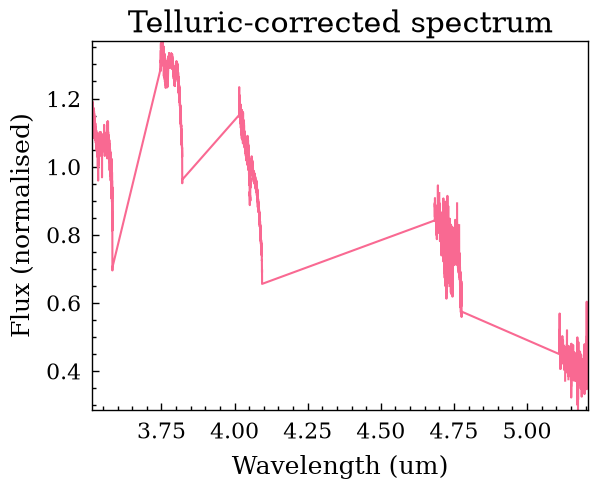

In [14]:
plt.close()
plt.plot(wavelength, observed_flux_norm)
plt.xlabel('Wavelength (um)')
plt.ylabel('Flux (normalised)')
plt.title('Telluric-corrected spectrum')
#plt.ylim(0, 2)
plt.show()

# Remove spikes (now done prior to telluric correction)

In [ ]:
# ### REMOVE SPIKES
# WINDOW = 15
# SPIKE_SIGMA = 8

# if WINDOW % 2 == 0:
#     raise ValueError('WINDOW must be an odd number')

# local_median = median_filter(observed_flux, size=WINDOW)
# residual = observed_flux - local_median

# local_residual_median = median_filter(
#     residual,
#     size=WINDOW,
#     mode="nearest",
# )
# absolute_deviation = np.abs(
#     residual - local_residual_median
# )
# local_mad = median_filter(
#     absolute_deviation,
#     size=WINDOW,
#     mode="nearest",
# )
# local_sigma = 1.4826 * local_mad #for normally distributed noise

# noise_scale = np.maximum(local_sigma, observed_error)
# spike_mask = (
#     np.abs(residual) > SPIKE_SIGMA * noise_scale
# )

# print(f"Spikes identified: {np.sum(spike_mask)}")

# fig, ax = plt.subplots(figsize=(14, 5))

# ax.plot(
#     wavelength,
#     observed_flux,
#     color="black",
#     linewidth=0.7,
#     label="Original spectrum",
# )

# ax.scatter(
#     wavelength[spike_mask],
#     observed_flux[spike_mask],
#     color="red",
#     s=25,
#     label="Flagged spikes",
#     zorder=3,
# )

# ax.plot(
#     wavelength,
#     local_median,
#     color="tab:blue",
#     linewidth=1,
#     alpha=0.8,
#     label="Local median",
# )

# ax.set_xlabel("Wavelength [um]")
# ax.set_ylabel("Flux")
# ax.set_title("Detecting extreme local spikes")
# ax.legend()
# ax.grid(alpha=0.2)

# plt.tight_layout()
# plt.show()

# 2) Load one of the CO cross-section CSVs (for 1 temperature)

In [17]:
model_file_1000K = '/home/alst3712/Opacity_spectra/data/processed/CO_T1000K.csv'
co_model_1000K = pd.read_csv(model_file_1000K)

cross_section = co_model_1000K['cross_section_cm2_molecule'].to_numpy()
model_wavelength = co_model_1000K['wavelength_um'].to_numpy()

# again, make sure they are ordered:

model_order = np.argsort(model_wavelength)
model_wavelength = model_wavelength[model_order]
cross_section = cross_section[model_order]

print(
    f"CO model wavelength range: "
    f"{model_wavelength.min():.5f}–"
    f"{model_wavelength.max():.5f} um"
)

## only care about the wavelengths that the data has:

inside = ((model_wavelength >= min_wavelength_obs) & 
        (model_wavelength <= max_wavelength_obs))

model_wavelength = model_wavelength[inside]
cross_section = cross_section[inside]

print(f'Range we need for our data: {np.min(model_wavelength):.4f} - {np.max(model_wavelength):.4f} um')

CO model wavelength range: 0.50003–29.99850 um
Range we need for our data: 3.5134 - 5.2100 um


# Create a grid

In [24]:
dlog_wavelength = 1 / (10000 * 5)

log_grid = np.arange(
    np.log(model_wavelength.min()),
    np.log(model_wavelength.max()),
    dlog_wavelength,
)

model_grid_wavelength = np.exp(log_grid)

# Interpolate the cross-section onto this grid.
cross_section_grid = np.interp(
    model_grid_wavelength,
    model_wavelength,
    cross_section,
)
print(cross_section_grid)

[2.75041220e-58 1.78291527e-47 3.56586620e-47 ... 1.91855558e-39
 1.21799377e-39 5.17417943e-40]


# 3) Convert the cross-section into an absorption specrum

[2.75041220e-70 1.78291527e-59 3.56586620e-59 ... 1.91855558e-51
 1.21799377e-51 5.17417943e-52]
[1. 1. 1. ... 1. 1. 1.]
[0. 0. 0. ... 0. 0. 0.]


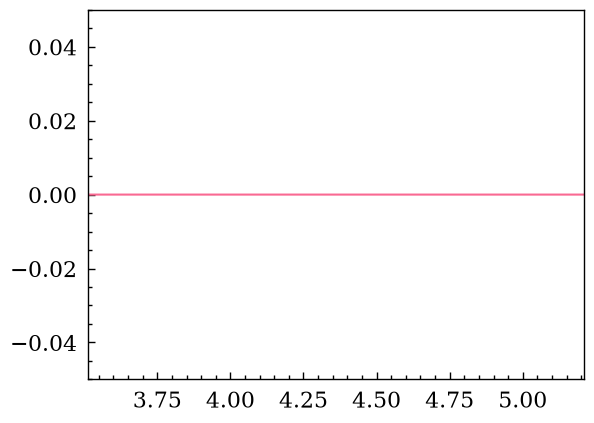

In [28]:
def make_co_template(column_density, c_f):
    # Optical depth:
    # tau = N_CO * sigma
    #
    # Units:
    # molecules/cm^2 * cm^2/molecule = dimensionless.

    optical_depth = column_density * cross_section_grid
    print(optical_depth)

    # Beer-Lambert law for pure absorption.

    # Partial covering:
    # a fraction f of the stellar continuum is covered by gas,
    # while the remaining fraction 1-f is unobscured.

    transmission = np.exp(-optical_depth)
    print(transmission)
    absorption = c_f * (1 - transmission)

    # Approximate instrumental broadening with a Gaussian line-spread
    # function. We convolve the transmission, not the optical depth.
    #
    # For resolving power R, the approximate Gaussian sigma in
    # log(wavelength) is 1 / (2.355 * R).

    # sigma_pixels = (
    #     1 / (2.355 * 10000)
    # ) / dlog_wavelength

    # transmission_broadened = gaussian_filter1d(
    #     transmission,
    #     sigma=sigma_pixels,
    #     mode="nearest",
    # )

    return absorption

plt.close()
absorption = make_co_template(1e-12, 0.5)
plt.plot(model_grid_wavelength, absorption)
print(absorption)
plt.show()

# 4) Inject CO absorption into observed specrum? And plot

In [7]:

def inject_co_signal(
    column_density, COVERING_FRACTION,
    injection_velocity=INJECTION_VELOCITY,
):
    """
    Add a synthetic CO absorption signal to the observed spectrum.

    The measured noise and its pixel-to-pixel variation are retained.
    """

    template_wavelength, template_flux = make_co_template(
        column_density, COVERING_FRACTION
    )

    # Doppler shift:
    # observed wavelength = rest wavelength * (1 + v/c)
    #
    # Therefore, to evaluate the template at an observed wavelength,
    # look up the template at wavelength / (1 + v/c).

    rest_wavelength = wavelength / (
        1 + injection_velocity / const.c.to('km/s').value
    )

    shifted_template = np.interp(
        rest_wavelength,
        template_wavelength,
        template_flux,
        left=1.0,
        right=1.0,
    )

    # The observed spectrum is normalised to approximately 1.
    # Add the model's absorption residual (template - 1).
    #
    # This preserves the existing noise fluctuations and uncertainty
    # array rather than generating new random noise.

    injected_flux = (
        observed_flux_norm + shifted_template - 1
    )

    return injected_flux, shifted_template

# plot

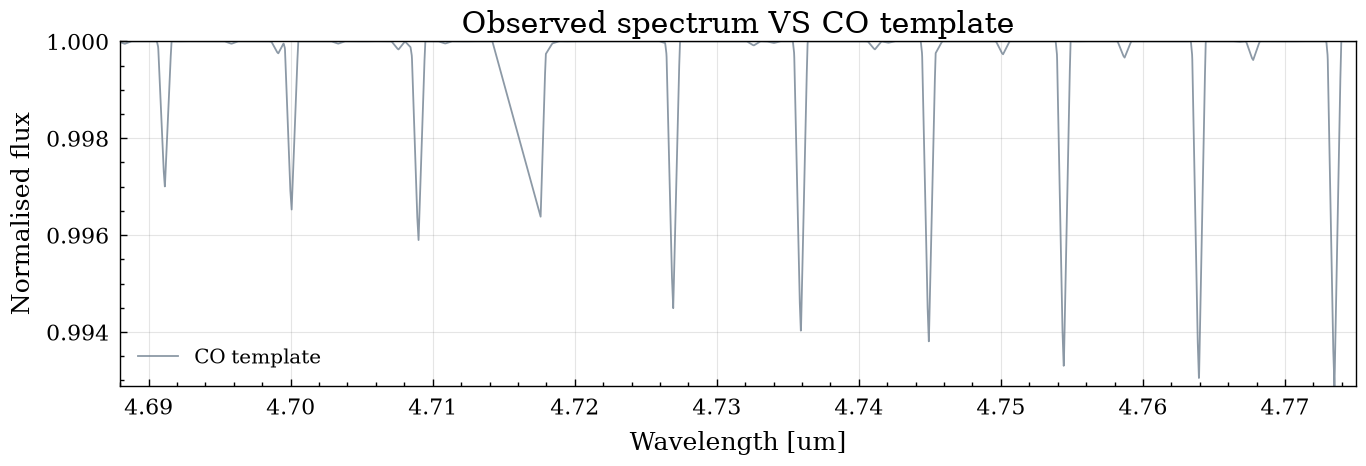

In [8]:
# Use one column density for the example plot.
PLOT_COLUMN_DENSITY = 1e16
COVERING_FRACTION = 0.8
injected_flux, injected_template = inject_co_signal(
    PLOT_COLUMN_DENSITY, COVERING_FRACTION
)
plt.close()

fig, ax = plt.subplots(figsize=(14, 5))

# ax.plot(
#     wavelength,
#     observed_flux_norm,
#     linewidth=0.8,
#     label="Observed spectrum",
#     color='firebrick'
# )


ax.plot(
    wavelength,
    injected_template,
    linewidth=1.3,
    alpha=0.8,
    label="CO template",
    color='slategrey'
)

ax.set_xlabel("Wavelength [um]")
ax.set_ylabel("Normalised flux")
ax.set_title("Observed spectrum VS CO template")
ax.legend()
ax.grid(alpha=0.2)
#ax.set_ylim(0.6, 1.1)
ax.set_xlim(4.688, 4.775)
plt.tight_layout()
plt.show()


# 5) Run the cross-correlation and plot